# 05 - Comparison, charts and error analysis

Reads only saved outputs (`results/metrics.csv`, `results/preds/*.csv`, the frozen splits). No model is retrained and no API call is made. All models were finalised before this notebook, so reading test-set errors here can't leak into model design.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import confusion_matrix

from src.data_utils import load_split, load_hard_cases, LABELS
from src.eval_utils import METRICS_PATH, PREDS_DIR, CHART_DIR, slugify

# Chart tokens (dataviz reference palette)
BLUE, INK, INK2, GRID = '#2a78d6', '#0b0b0b', '#52514e', '#e6e5e0'
SEQ_BLUE = LinearSegmentedColormap.from_list(
    'seq_blue', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])

BASELINE = 'Majority baseline'
MODELS = ['VADER', 'TextBlob', 'NLTK + Naive Bayes', 'LLM zero-shot (Haiku 5.5)']
MAIN = ['VADER', 'NLTK + Naive Bayes', 'LLM zero-shot (Haiku 5.5)']  # one per tier
SHORT = {'VADER': 'VADER', 'TextBlob': 'TextBlob', 'NLTK + Naive Bayes': 'Naive Bayes',
         'LLM zero-shot (Haiku 5.5)': 'LLM (Haiku 5.5)'}

## 1. Results table (the centerpiece)

In [2]:
metrics = pd.read_csv(METRICS_PATH).set_index('model').loc[[BASELINE] + MODELS]
tier = {BASELINE: '-', 'VADER': '1 Rule-based', 'TextBlob': '1 Rule-based',
        'NLTK + Naive Bayes': '2 Classic ML', 'LLM zero-shot (Haiku 5.5)': '3 LLM'}
table = pd.DataFrame({
    'Tier': [tier[m] for m in metrics.index],
    'Accuracy': metrics['accuracy'].map('{:.3f}'.format),
    'Macro-F1': metrics['macro_f1'].map('{:.3f}'.format),
    'Hard-cases acc.': metrics['hard_cases_acc'].map('{:.2f}'.format),
    'Sec / 1k preds': metrics['sec_per_1k'].map(lambda s: f'{s:,.1f}' if s >= 0.1 else '<0.1'),
    'Cost / 1k preds': metrics['cost_per_1k'].map(lambda c: f'${c:.3f}' if c > 0 else '$0'),
}, index=metrics.index).rename_axis('Model')
# Save a Markdown copy for the report (built by hand: no tabulate dependency)
header = ['Model'] + list(table.columns)
lines = ['| ' + ' | '.join(header) + ' |', '|' + '---|' * len(header)]
lines += ['| ' + ' | '.join([m, *row]) + ' |' for m, row in zip(table.index, table.to_numpy())]
(Path(METRICS_PATH).parent / 'results_table.md').write_text('\n'.join(lines) + '\n', encoding='utf-8')
table

,Tier,Accuracy,Macro-F1,Hard-cases acc.,Sec / 1k preds,Cost / 1k preds
Model,,,,,,
Majority baseline,-,0.503,0.335,0.50,<0.1,$0
VADER,1 Rule-based,0.727,0.715,0.33,4.7,$0
TextBlob,1 Rule-based,0.710,0.687,0.40,2.1,$0
NLTK + Naive Bayes,2 Classic ML,0.887,0.887,0.70,4.2,$0
LLM zero-shot (Haiku 5.5),3 LLM,0.957,0.957,1.00,"1,560.3",$0.075


## 2. Charts

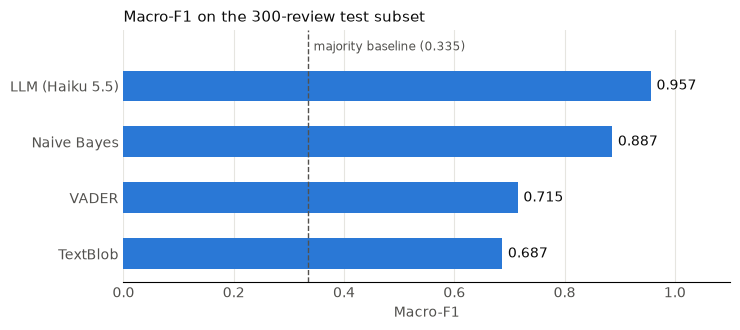

In [3]:
def bar_chart(values, title, xlabel, fname, baseline=None, fmt='{:.3f}'):
    """Single-series horizontal bars (one hue), direct value labels, baseline as a reference line."""
    values = values.sort_values()
    fig, ax = plt.subplots(figsize=(7.5, 3.4))
    ax.barh([SHORT[m] for m in values.index], values, height=0.55, color=BLUE)
    for y, v in enumerate(values):
        ax.text(v + 0.01, y, fmt.format(v), va='center', fontsize=10, color=INK)
    ax.set_ylim(-0.5, len(values) - 0.5 + 0.5)  # headroom above the top bar for the baseline label
    if baseline is not None:
        ax.axvline(baseline, color=INK2, linestyle='--', linewidth=1)
        ax.text(baseline + 0.01, len(values) - 0.42, f'majority baseline ({fmt.format(baseline)})',
                fontsize=8.5, color=INK2, va='bottom')
    ax.set_xlim(0, 1.1)
    ax.set_title(title, loc='left', fontsize=11, color=INK)
    ax.set_xlabel(xlabel, color=INK2)
    ax.grid(axis='x', color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ('top', 'right', 'left'):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=INK2, length=0)
    fig.tight_layout()
    fig.savefig(CHART_DIR / fname, dpi=150, bbox_inches='tight')
    plt.show()

bar_chart(metrics.loc[MODELS, 'macro_f1'], 'Macro-F1 on the 300-review test subset',
          'Macro-F1', 'compare_macro_f1.png', baseline=metrics.loc[BASELINE, 'macro_f1'])

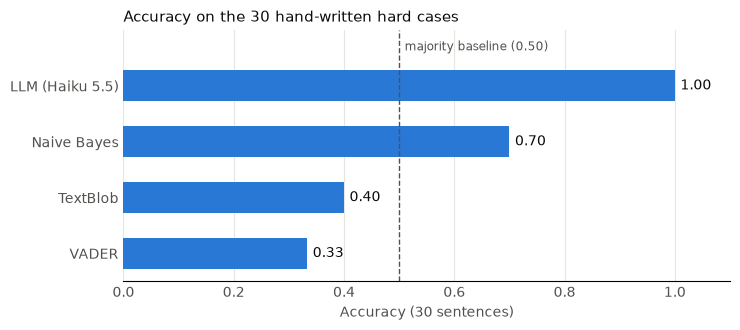

In [4]:
bar_chart(metrics.loc[MODELS, 'hard_cases_acc'], 'Accuracy on the 30 hand-written hard cases',
          'Accuracy (30 sentences)', 'compare_hard_cases.png',
          baseline=metrics.loc[BASELINE, 'hard_cases_acc'], fmt='{:.2f}')

### 2.1 Hard-case accuracy by category

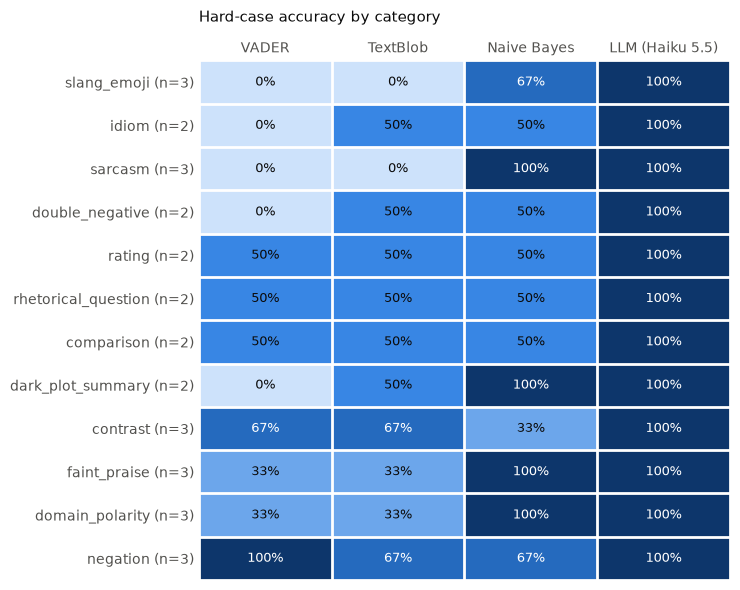

In [5]:
preds = {m: pd.read_csv(PREDS_DIR / f'{slugify(m)}.csv', keep_default_na=False) for m in MODELS}
hard = load_hard_cases()
cat_acc = pd.DataFrame({
    SHORT[m]: p[p['split'] == 'hard'].groupby('category')['correct'].mean()
    for m, p in preds.items()
})
cat_acc = cat_acc.loc[cat_acc.mean(axis=1).sort_values().index]  # hardest first
n_per_cat = hard['category'].value_counts()

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.imshow(cat_acc.to_numpy(), cmap=SEQ_BLUE, vmin=0, vmax=1, aspect='auto')
for i in range(cat_acc.shape[0]):
    for j in range(cat_acc.shape[1]):
        v = cat_acc.iat[i, j]
        ax.text(j, i, f'{v:.0%}', ha='center', va='center', fontsize=9.5,
                color='white' if v > 0.6 else INK)
ax.set_xticks(range(cat_acc.shape[1]), cat_acc.columns)
ax.set_yticks(range(cat_acc.shape[0]),
              [f'{c} (n={n_per_cat[c]})' for c in cat_acc.index])
ax.xaxis.tick_top()
ax.tick_params(colors=INK2, length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks(np.arange(-0.5, cat_acc.shape[1]), minor=True)
ax.set_yticks(np.arange(-0.5, cat_acc.shape[0]), minor=True)
ax.grid(which='minor', color='white', linewidth=2)  # 2px surface gap between cells
ax.tick_params(which='minor', length=0)
ax.set_title('Hard-case accuracy by category', loc='left', fontsize=11, color=INK, pad=28)
fig.tight_layout()
fig.savefig(CHART_DIR / 'compare_hard_case_categories.png', dpi=150, bbox_inches='tight')
plt.show()

### 2.2 Confusion matrices (test300)

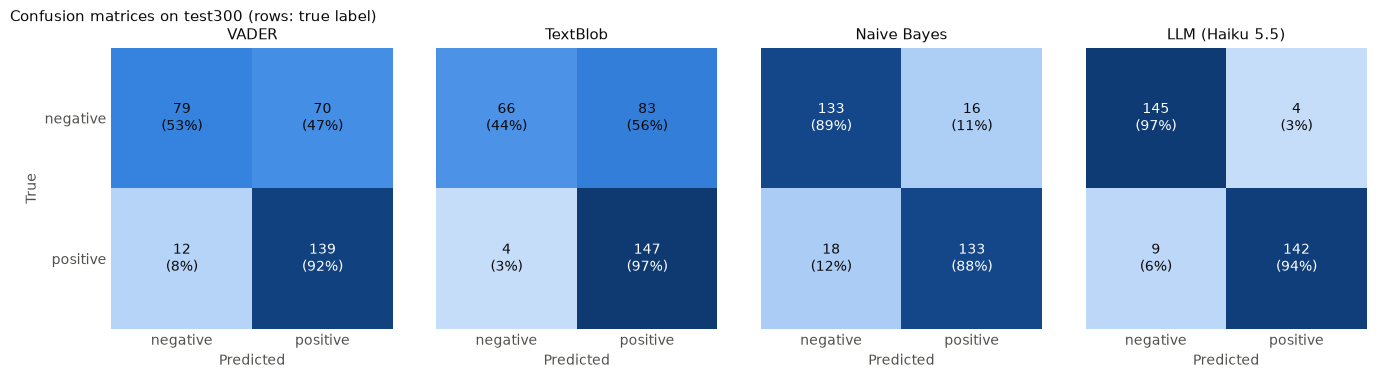

In [6]:
test = load_split('test300')
fig, axes = plt.subplots(1, len(MODELS), figsize=(14, 3.6))
for ax, m in zip(axes, MODELS):
    p = preds[m][preds[m]['split'] == 'test300']
    cm = confusion_matrix(p['label'], p['pred'], labels=LABELS)
    ax.imshow(cm, cmap=SEQ_BLUE, vmin=0, vmax=151)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]}\n({cm[i, j] / cm[i].sum():.0%})', ha='center',
                    va='center', fontsize=10, color='white' if cm[i, j] > 83 else INK)
    ax.set_xticks([0, 1], LABELS)
    ax.set_yticks([0, 1], LABELS if ax is axes[0] else ['', ''])
    ax.set_title(SHORT[m], fontsize=10.5, color=INK)
    ax.set_xlabel('Predicted', color=INK2)
    ax.tick_params(colors=INK2, length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
axes[0].set_ylabel('True', color=INK2)
fig.suptitle('Confusion matrices on test300 (rows: true label)', x=0.01, ha='left',
             fontsize=11, color=INK)
fig.tight_layout()
fig.savefig(CHART_DIR / 'compare_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Error analysis on test300
### 3.1 Error direction

In [7]:
t = {m: preds[m][preds[m]['split'] == 'test300'].reset_index(drop=True) for m in MODELS}
for m in MODELS:
    assert (t[m]['label'].to_numpy() == test['label'].to_numpy()).all()  # aligned with test300
pd.DataFrame({
    SHORT[m]: {
        'errors': int((~t[m]['correct']).sum()),
        'neg -> pos (false positive)': int(((t[m]['label'] == 'negative') & (t[m]['pred'] == 'positive')).sum()),
        'pos -> neg (false negative)': int(((t[m]['label'] == 'positive') & (t[m]['pred'] == 'negative')).sum()),
        'share of predictions positive': round((t[m]['pred'] == 'positive').mean(), 3),
    } for m in MODELS
}).T

,errors,neg -> pos (false positive),pos -> neg (false negative),share of predictions positive
VADER,82.0,70.0,12.0,0.697
TextBlob,87.0,83.0,4.0,0.767
Naive Bayes,34.0,16.0,18.0,0.497
LLM (Haiku 5.5),13.0,4.0,9.0,0.487


### 3.2 Do the tiers fail on the same reviews?
This uses one model per tier (VADER, Naive Bayes, LLM).

In [8]:
wrong = pd.DataFrame({SHORT[m]: ~t[m]['correct'] for m in MAIN})
pattern = wrong.apply(lambda r: ' + '.join(c for c in wrong.columns if r[c]) or 'none wrong', axis=1)
overlap = pattern.value_counts().rename('reviews').to_frame()
overlap['share'] = (overlap['reviews'] / len(wrong)).round(3)
overlap

,reviews,share
none wrong,193,0.643
VADER,65,0.217
Naive Bayes,16,0.053
VADER + Naive Bayes,13,0.043
Naive Bayes + LLM (Haiku 5.5),5,0.017
LLM (Haiku 5.5),4,0.013
VADER + LLM (Haiku 5.5),4,0.013


In [9]:
v, nb_, lm = (wrong[SHORT[m]] for m in MAIN)
print(f'LLM fixes {int((nb_ & ~lm).sum())} of Naive Bayes\'s {int(nb_.sum())} errors; '
      f'it introduces {int((lm & ~nb_).sum())} new ones.')
print(f'Naive Bayes fixes {int((v & ~nb_).sum())} of VADER\'s {int(v.sum())} errors; '
      f'it introduces {int((nb_ & ~v).sum())} new ones.')
print(f'All three tiers wrong on {int((v & nb_ & lm).sum())} reviews.')
oracle = 1 - (v & nb_ & lm).mean()
print(f'Upper bound if we always picked the right tier: {oracle:.3f} accuracy')

LLM fixes 29 of Naive Bayes's 34 errors; it introduces 8 new ones.
Naive Bayes fixes 69 of VADER's 82 errors; it introduces 21 new ones.
All three tiers wrong on 0 reviews.
Upper bound if we always picked the right tier: 1.000 accuracy


**Is the LLM's lead over Naive Bayes real on only 300 reviews?** An exact McNemar test uses only the reviews where the two models disagree.

In [10]:
from scipy.stats import binomtest

def mcnemar(a_wrong, b_wrong, a, b):
    only_a, only_b = int((a_wrong & ~b_wrong).sum()), int((b_wrong & ~a_wrong).sum())
    p = binomtest(min(only_a, only_b), only_a + only_b, 0.5).pvalue
    print(f'{a} wrong only: {only_a:>3} | {b} wrong only: {only_b:>3} | exact McNemar p = {p:.2g}')

mcnemar(nb_, lm, 'Naive Bayes', 'LLM')
mcnemar(v, nb_, 'VADER', 'Naive Bayes')

Naive Bayes wrong only:  29 | LLM wrong only:   8 | exact McNemar p = 0.00075
VADER wrong only:  69 | Naive Bayes wrong only:  21 | exact McNemar p = 3.9e-07


### 3.3 Accuracy by review length
Length thirds of test300, by word count.

In [11]:
words = test['text'].str.split().str.len()
length_bin = pd.qcut(words, 3, labels=['short', 'medium', 'long'])
bins = words.groupby(length_bin, observed=True).agg(['min', 'max', 'size'])
by_len = pd.DataFrame({SHORT[m]: t[m]['correct'].groupby(length_bin, observed=True).mean()
                       for m in MODELS}).round(3)
pd.concat([bins.rename(columns={'min': 'min words', 'max': 'max words', 'size': 'n'}), by_len], axis=1)

,min words,max words,n,VADER,TextBlob,Naive Bayes,LLM (Haiku 5.5)
text,,,,,,,
short,36,136,100,0.82,0.76,0.85,0.93
medium,137,214,100,0.76,0.79,0.92,0.96
long,219,980,100,0.60,0.58,0.89,0.98


### 3.4 Reading the errors
Excerpts truncated to 350 characters. **(a)** LLM errors, **(b)** reviews all three tiers got wrong, **(c)** a sample of reviews Naive Bayes got wrong but the LLM got right.

In [12]:
def show(mask, title, n=None):
    rows = test[mask.to_numpy()].assign(
        words=words[mask.to_numpy()],
        **{SHORT[m]: t[m]['pred'][mask.to_numpy()] for m in MAIN})
    if n:
        rows = rows.sample(min(n, len(rows)), random_state=42)
    print(f'===== {title} ({mask.sum()} reviews) =====')
    for i, r in rows.iterrows():
        preds_str = ', '.join(f'{SHORT[m]}={r[SHORT[m]]}' for m in MAIN)
        excerpt = r['text'] if len(r['text']) <= 350 else r['text'][:350] + '...'
        print(f"\n[#{i}] true={r['label']} | {preds_str} | {r['words']} words\n{excerpt}")

show(lm, '(a) LLM errors')

===== (a) LLM errors (13 reviews) =====

[#38] true=negative | VADER=negative, Naive Bayes=negative, LLM (Haiku 5.5)=positive | 193 words
People don't seem to agree with me that movies can be bad and good at the same time. The same type of people that see a movie with Carrot Top on the cover, surfing through a frickin office and continue to watch the movie with serious expectations. Is Carrot Top funny? Of course not. Was this movie anything special? Of course not. It was a dumb movi...

[#61] true=positive | VADER=positive, Naive Bayes=positive, LLM (Haiku 5.5)=negative | 129 words
I saw this movie when it first came out in 1973 and loved it. Since then I've searched for a video but never found it until now, 33 years later, when I ordered it from Moviehunter. Sorry to say it doesn't hold up. This glamourized version just can't rise up to the 1937 production level. I love Burt Bacharach's musical score, that is if listend to b...

[#84] true=positive | VADER=positive, Naive Bayes=negat

In [13]:
show(v & nb_ & lm, '(b) all three tiers wrong')

===== (b) all three tiers wrong (0 reviews) =====


In [14]:
show(nb_ & ~lm, '(c) Naive Bayes wrong, LLM right (sample of 6)', n=6)

===== (c) Naive Bayes wrong, LLM right (sample of 6) (29 reviews) =====

[#279] true=positive | VADER=positive, Naive Bayes=negative, LLM (Haiku 5.5)=positive | 63 words
Well I gave this movie a 7. It was better than "Thirdspace" but not as good as "In the Beginning" as far as the B5 movies go. I really think the television series did a much better job overall with the special effects and character portrayal. Let's hope the producers and cast get the next series "Crusade" up to the standards of B5.

[#169] true=positive | VADER=positive, Naive Bayes=negative, LLM (Haiku 5.5)=positive | 434 words
So forgive the *really* lame game-play scene, cardboard background and studio like stadium. For this part I should have give the movie 5 instead of 7, but read on... From the premise to plot there is a lot similarities with "The Replacements". Some say this movie rip off "The Replacements", while some say this script wrote before it. Both movies re...

[#120] true=negative | VADER=positive, Nai

## 4. What would each model cost at scale?
Linear extrapolation from the measured per-1k figures. LLM throughput is shown both sequential (as in the table) and with 4 parallel workers, as measured in `04_llm`.

In [15]:
volumes = [1_000, 100_000, 1_000_000]
rows = []
for m in MAIN:
    sec, cost = metrics.loc[m, 'sec_per_1k'], metrics.loc[m, 'cost_per_1k']
    for n in volumes:
        rows.append({'model': SHORT[m], 'reviews': f'{n:,}',
                     'time (sequential)': pd.Timedelta(seconds=sec * n / 1000).round('s'),
                     'time (4 workers)': (pd.Timedelta(seconds=sec / 4 * n / 1000).round('s')
                                          if m.startswith('LLM') else '-'),
                     'cost (USD)': round(cost * n / 1000, 2)})
pd.DataFrame(rows).set_index(['model', 'reviews'])

time (sequential) time (4 workers)  cost (USD)
model           reviews                                                 
VADER           1,000       0 days 00:00:05                -        0.00
                100,000     0 days 00:07:48                -        0.00
                1,000,000   0 days 01:17:55                -        0.00
Naive Bayes     1,000       0 days 00:00:04                -        0.00
                100,000     0 days 00:06:58                -        0.00
                1,000,000   0 days 01:09:43                -        0.00
LLM (Haiku 5.5) 1,000       0 days 00:26:00  0 days 00:06:30        0.08
                100,000     1 days 19:20:30  0 days 10:50:08        7.50
                1,000,000  18 days 01:25:01  4 days 12:21:15       75.00

## 5. Findings

**1. Each tier is a significant step up.**

| | Macro-F1 | Gain | Errors fixed / introduced vs previous tier | Exact McNemar p |
|---|---|---|---|---|
| VADER | 0.715 | +0.38 vs baseline | | |
| Naive Bayes | 0.887 | +0.17 | 69 fixed / 21 new | 4e-7 |
| LLM (Haiku 5.5) | 0.957 | +0.07 | 29 fixed / 8 new | 0.0008 |

Even with only 300 test reviews, both gaps are far beyond chance.

**2. The errors are nested, not random.**
- 193 of 300 reviews (64%) were classified correctly by all three tiers. **None** was missed by all three.
- 65 errors belong to VADER alone. These are mostly long negative reviews containing plenty of positive words, and any trained model handles them.
- Only 4 reviews tripped the LLM alone.

**3. Error direction tells the story of each method.**
- The lexicons call 70% (VADER) and 77% (TextBlob) of reviews positive, even though the test set is 50/50. Positive words outnumber negative ones even in bad reviews.
- Naive Bayes (49.7%) and the LLM (48.7%) are balanced.

**4. Length affects each method differently.**

| Accuracy by review length | Short (36–136 words) | Medium (137–214) | Long (219–980) |
|---|---|---|---|
| VADER | 0.82 | 0.76 | **0.60** |
| Naive Bayes | 0.85 | 0.92 | 0.89 |
| LLM | 0.93 | 0.96 | **0.98** |

VADER *degrades* with length because its positive bias accumulates. The LLM *improves* with length because more context gives it more of the reviewer's verdict. Naive Bayes is roughly flat.

**5. Hard cases.**
- Lexicons fail on anything non-literal: sarcasm, slang/emoji, idioms and dark plot summaries each score 0% for VADER.
- Naive Bayes learned some of these from data (sarcasm, faint praise, domain polarity and dark plot all 100%). It still fails on contrast (33%) and on short positive sentences containing one negative word.
- The LLM got all 30 right, with the caveat from `04_llm` that the cases were written by an LLM.

**6. What the LLM gets wrong** (13 reviews, read in §3.4). Many are arguably label noise rather than model failure:
- **The text disagrees with the star rating.** IMDB labels come from the star rating, not the text. Examples: #61 "loved it in 1973… Sorry to say it doesn't hold up" is labelled positive; #205 "I felt unsatisfied… I came to find it lacking" is labelled positive. A human reading only the text would likely side with the LLM.
- **"So bad it's good."** Examples: #269 Carnosaur 3 ("if you enjoy the very worst of the worst, this is for you") and #38 Carrot Top. The reviewer recommends the film ironically but rated it low. The LLM took the recommendation at face value.
- **Grim subject, positive verdict.** Examples: #148 "A truly scary film" (about oil depletion) and #213 "haunted me for 50 years". Unlike the short hard cases, the praise here is outweighed by long passages of dark content.
- **Off-target reviews.** Examples: #124 complains about a show being cancelled, and #93 defends TV crews. The sentiment is about something other than the film.

**7. Where the LLM beats Naive Bayes** (29 reviews, sample in §3.4):
- Concessive structure: "Neither the total disaster… nor the misunderstood masterpiece", and "The photography is accomplished, the acting is quite good, but… a dreary bore".
- Ratings stated in words: "I gave this movie a 7".
- Positive reviews that spend many words on complaints.
- In each case the verdict depends on how the clauses relate, which a bag of words can't see.

**8. At scale, the LLM's real cost is time, not money.**

| 1M reviews | Time | Cost |
|---|---|---|
| Naive Bayes, 1 laptop CPU | about 70 minutes | $0 |
| LLM, sequential | about 18 days | $75 |
| LLM, 4 parallel workers | about 4.5 days | $75 |

At $0.075 per 1,000, Haiku 5.5 is cheap. Throughput, rate limits and network dependency are the binding constraints. For offline jobs the Message Batches API would halve the cost and remove the need to manage concurrency.

**Draft answer to the project question**
- **When a simple model is good enough.** Naive Bayes is enough for high-volume, low-latency, in-domain work where labelled data exists and ~89% accuracy is acceptable: dashboards, trend tracking, triage. It runs locally, instantly and for free.
- **When the LLM earns its cost.** When there is no labelled data or the domain is new; when text is nuanced (contrast, sarcasm, mixed verdicts); or when each error is expensive. At $0.075 per 1,000 it is affordable for almost any volume where 26 minutes per 1,000 sequential calls, or batch processing, is acceptable.
- **When VADER fits.** Only as a zero-setup baseline, or for short, literal text. On long reviews it is barely better than a coin flip on the negative class (53% recall).